# UTP : Praktikum Pengantar Data Mining

- **Nama** : Claudia Sabattini Sagala
- **NIM**  : 245090400111048

# **1. Import Library**

Pada tahap ini, Anda perlu mengimpor beberapa pustaka (library) Python yang dibutuhkan untuk analisis data dan pembangunan model machine learning.

In [ ]:
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import silhouette_score
import warnings
warnings.filterwarnings('ignore')

# **2. Memuat Dataset**

In [ ]:
df = pd.read_csv('DATASET_UTP_PPDM.csv')
df.head()

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


# **3. Exploratory Data Analysis (EDA)**

In [ ]:
#mengetahui struktur data dan tipe kolom
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950 non-null   int64  
 12  PURCHA

In [ ]:
#statistik deskriptif
display(df.describe())

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [ ]:
# Menampilkan 5 baris pertama dan terakhir
display(df.head())
display(df.tail())

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.50,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.00,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.25,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.25,6
8949,C19190,372.708075,0.666667,1093.25,1093.25,0.00,127.040008,0.666667,0.666667,0.000000,0.333333,2,23,1200.0,63.165404,88.288956,0.00,6


In [ ]:
# Pengecekan missing values
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df)) * 100
missing_summary = pd.DataFrame({
    'Total Missing': missing_values,
    'Missing Percentage (%)': missing_percentage.round(2)
})
missing_summary = missing_summary[missing_summary['Total Missing'] > 0]

print('Kolom dengan Missing Values:')
print(missing_summary)

# Pengecekan duplikasi
print(f'\nJumlah data duplikat: {df.duplicated().sum()}')

Kolom dengan Missing Values:
                  Total Missing  Missing Percentage (%)
CREDIT_LIMIT                  1                    0.01
MINIMUM_PAYMENTS            313                    3.50

Jumlah data duplikat: 0


**Temuan**: Terdapat 2 kolom yang memiliki missing values:
- `CREDIT_LIMIT`: 1 data hilang (~0.01%)
- `MINIMUM_PAYMENTS`: 313 data hilang (~3.50%)

Tidak ada data duplikat pada dataset ini.

In [ ]:
# Identifikasi kolom numerik
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns.tolist()
print(f'Kolom numerik ({len(numerical_cols)} kolom):')
print(numerical_cols)

Kolom numerik (17 kolom):
['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']


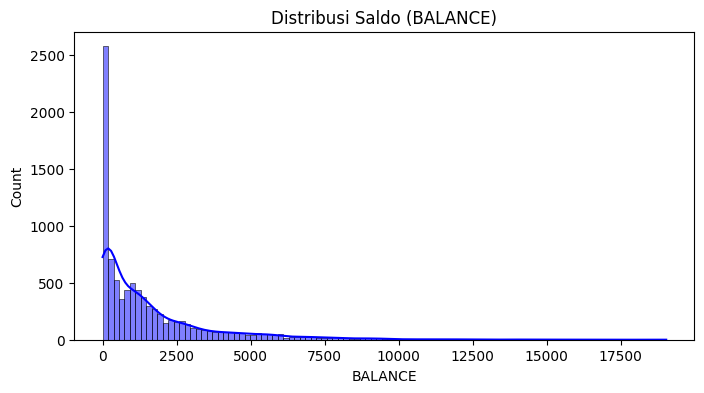

In [ ]:
# 1. Distribusi Kolom Numerik (Contoh: BALANCE)
plt.figure(figsize=(8, 4))
sns.histplot(df['BALANCE'], kde=True, color='blue')
plt.title('Distribusi Saldo (BALANCE)')
plt.show()

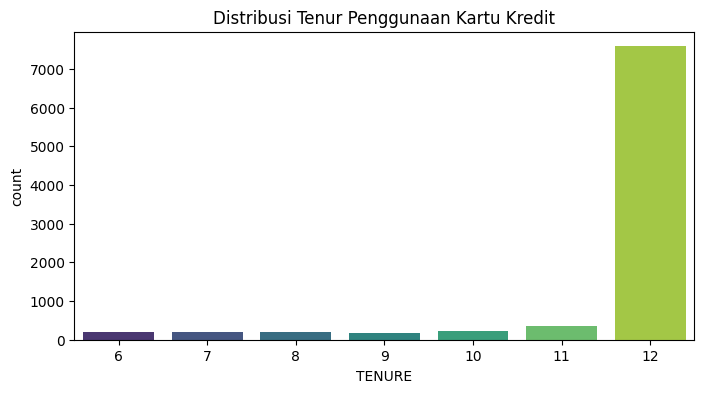

In [ ]:
# 2. Distribusi Kolom Kategorik/Ordinal (Contoh: TENURE)
plt.figure(figsize=(8, 4))
sns.countplot(x='TENURE', data=df, palette='viridis')
plt.title('Distribusi Tenur Penggunaan Kartu Kredit')
plt.show()

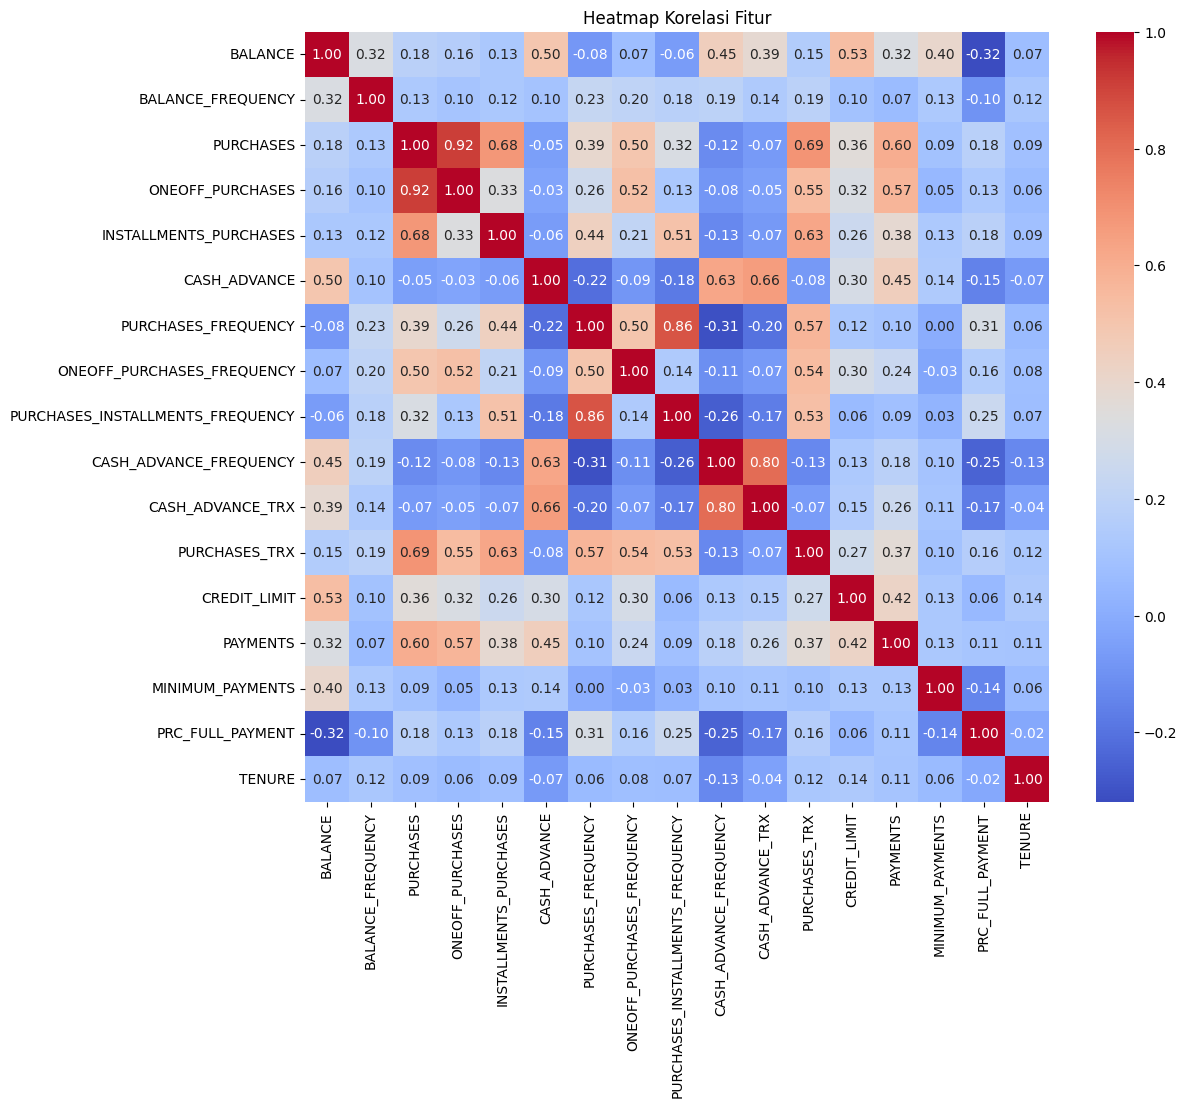

In [ ]:
# 3. Korelasi Antar Variabel (Heatmap)
plt.figure(figsize=(12, 10))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Heatmap Korelasi Fitur')
plt.show()

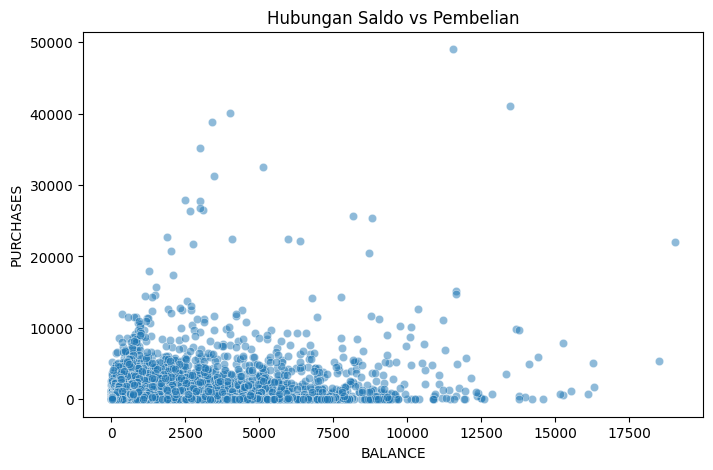

In [ ]:
# 4. Hubungan antara Saldo dan Pembelian
plt.figure(figsize=(8, 5))
sns.scatterplot(x='BALANCE', y='PURCHASES', data=df, alpha=0.5)
plt.title('Hubungan Saldo vs Pembelian')
plt.show()

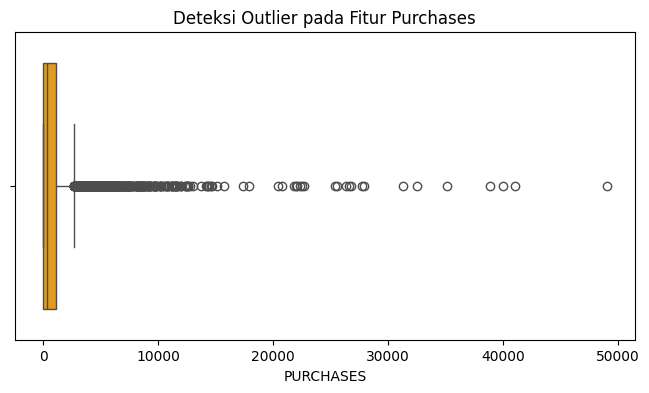

In [ ]:
# 5. Boxplot untuk deteksi Outlier pada fitur utama
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['PURCHASES'], color='orange')
plt.title('Deteksi Outlier pada Fitur Purchases')
plt.show()

5 Insights Berdasarkan Visualisasi:
1. Pola Saldo: Mayoritas pelanggan memiliki saldo kartu kredit di rentang rendah, namun terdapat ekor panjang (skewed) yang menunjukkan adanya kelompok kecil dengan saldo sangat tinggi.
2. Loyalitas Pelanggan: Distribusi TENURE menunjukkan bahwa sebagian besar pelanggan telah menggunakan layanan kartu kredit selama 12 bulan (maksimal), menandakan retensi yang baik.
3. Korelasi Pembelian: Terdapat korelasi positif yang sangat kuat antara PURCHASES dan ONEOFF_PURCHASES, yang berarti mayoritas pembelian dilakukan secara tunai/sekali bayar daripada cicilan.
4. Aktivitas Penarikan Tunai: Fitur CASH_ADVANCE memiliki korelasi rendah dengan pembelian retail, menunjukkan adanya perbedaan perilaku antara pelanggan yang belanja dan pelanggan yang menggunakan kartu untuk pinjaman tunai.
5. Adanya Pencilan (Outliers): Visualisasi boxplot menunjukkan banyak data pencilan pada nominal transaksi (PURCHASES), yang mengindikasikan adanya segmen pelanggan "Premium" atau "Whales"

# **4. Data Preprocessing**

Pada tahap ini, data preprocessing adalah langkah penting untuk memastikan kualitas data sebelum digunakan dalam model machine learning. Data mentah sering kali mengandung nilai kosong, duplikasi, atau rentang nilai yang tidak konsisten, yang dapat memengaruhi kinerja model. Oleh karena itu, proses ini bertujuan untuk membersihkan dan mempersiapkan data agar analisis berjalan optimal.

Berikut adalah tahapan-tahapan yang bisa dilakukan, tetapi **tidak terbatas** pada:
1. Menghapus atau Menangani Data Kosong (Missing Values)
2. Menghapus Data Duplikat
3. Normalisasi atau Standarisasi Fitur
4. Deteksi dan Penanganan Outlier
5. Encoding Data Kategorikal
6. Binning (Pengelompokan Data)

Cukup sesuaikan dengan karakteristik data yang kamu gunakan.

Kolom `CUST_ID` merupakan identitas unik nasabah (kategorikal) yang tidak memberikan informasi analitik untuk clustering. Kolom ini dihapus.

In [ ]:
# 1. Menghapus kolom identitas unik (Noise Reduction)
df_clean = df.copy()
df_clean.drop(columns=['CUST_ID'], inplace=True)
print(f'Dimensi setelah menghapus CUST_ID : {df_clean.shape}')
print(f'Kolom tersisa: {df_clean.columns.tolist()}')

Dimensi setelah menghapus CUST_ID : (8950, 17)
Kolom tersisa: ['BALANCE', 'BALANCE_FREQUENCY', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE', 'PURCHASES_FREQUENCY', 'ONEOFF_PURCHASES_FREQUENCY', 'PURCHASES_INSTALLMENTS_FREQUENCY', 'CASH_ADVANCE_FREQUENCY', 'CASH_ADVANCE_TRX', 'PURCHASES_TRX', 'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS', 'PRC_FULL_PAYMENT', 'TENURE']


Strategi penanganan missing values disesuaikan dengan distribusi data:
- `CREDIT_LIMIT` dan `MINIMUM_PAYMENTS`: diisi dengan **median** karena distribusinya tidak normal (skewed).

Penggunaan median lebih tepat untuk data skewed karena tidak terpengaruh nilai ekstrim (outlier).

In [ ]:
# 2. Penanganan Missing Value
print('Missing values SEBELUM imputasi:')
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])
median_credit_limit = df_clean['CREDIT_LIMIT'].median()
df_clean['CREDIT_LIMIT'] = df_clean['CREDIT_LIMIT'].fillna(median_credit_limit)
print(f'\nMedian CREDIT_LIMIT untuk imputasi     : {median_credit_limit}')
median_min_payments = df_clean['MINIMUM_PAYMENTS'].median()
df_clean['MINIMUM_PAYMENTS'] = df_clean['MINIMUM_PAYMENTS'].fillna(median_min_payments)
print(f'Median MINIMUM_PAYMENTS untuk imputasi : {median_min_payments:.4f}')
print(f'\nMissing values SETELAH imputasi: {df_clean.isnull().sum().sum()} total missing values tersisa')

Missing values SEBELUM imputasi:
CREDIT_LIMIT          1
MINIMUM_PAYMENTS    313
dtype: int64

Median CREDIT_LIMIT untuk imputasi     : 3000.0
Median MINIMUM_PAYMENTS untuk imputasi : 312.3439

Missing values SETELAH imputasi: 0 total missing values tersisa


In [ ]:
# 3. Penanganan Outlier menggunakan IQR (Interquartile Range)
# Deteksi outlier per kolom
outlier_report = {}
for col in df_clean.columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    outlier_report[col] = n_outliers

outlier_df = pd.DataFrame.from_dict(outlier_report, orient='index', columns=['Jumlah Outlier'])
outlier_df['Persentase (%)'] = (outlier_df['Jumlah Outlier'] / len(df_clean) * 100).round(2)
print('Jumlah Outlier per Kolom:')
print(outlier_df[outlier_df['Jumlah Outlier'] > 0])

Jumlah Outlier per Kolom:
                            Jumlah Outlier  Persentase (%)
BALANCE                                695            7.77
BALANCE_FREQUENCY                     1493           16.68
PURCHASES                              808            9.03
ONEOFF_PURCHASES                      1013           11.32
INSTALLMENTS_PURCHASES                 867            9.69
CASH_ADVANCE                          1030           11.51
ONEOFF_PURCHASES_FREQUENCY             782            8.74
CASH_ADVANCE_FREQUENCY                 525            5.87
CASH_ADVANCE_TRX                       804            8.98
PURCHASES_TRX                          766            8.56
CREDIT_LIMIT                           248            2.77
PAYMENTS                               808            9.03
MINIMUM_PAYMENTS                       909           10.16
PRC_FULL_PAYMENT                      1474           16.47
TENURE                                1366           15.26


In [ ]:
# Capping outlier dengan batas IQR (Winsorizing)
df_processed = df_clean.copy()

for col in df_processed.columns:
    Q1 = df_processed[col].quantile(0.25)
    Q3 = df_processed[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df_processed[col] = df_processed[col].clip(lower=lower, upper=upper)

print(f'Dimensi setelah capping outlier: {df_processed.shape}')
print('\nVerifikasi statistik setelah capping:')
df_processed.describe()

Dimensi setelah capping outlier: (8950, 17)

Verifikasi statistik setelah capping:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.0
mean,1390.508973,0.931587,737.149330,354.358139,295.546214,672.468924,0.490351,0.184773,0.364437,0.126061,2.383128,11.623799,4419.137221,1347.084165,556.752385,0.087223,12.0
std,1537.538479,0.110984,879.534788,511.823289,396.181546,998.514970,0.401371,0.255668,0.397448,0.172676,3.417878,13.041645,3383.788645,1272.806272,532.174180,0.138616,0.0
min,0.000000,0.722223,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,12.0
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,170.857654,0.000000,12.0
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.0
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,788.713501,0.142857,12.0
max,4942.927215,1.000000,2715.872500,1443.512500,1171.593750,2784.552848,1.000000,0.750000,1.000000,0.555555,10.000000,41.000000,13850.000000,4177.921543,1715.497271,0.357143,12.0


In [ ]:
#4. Pemilihan Fitur
selected_features = ['BALANCE', 'PURCHASES', 'CASH_ADVANCE']

df_selected = df_processed[selected_features].copy()
print(f'Fitur yang dipilih untuk clustering: {selected_features}')
print(f'Dimensi data setelah feature selection: {df_selected.shape}')
print('\nStatistik fitur terpilih:')
df_selected.describe()

Fitur yang dipilih untuk clustering: ['BALANCE', 'PURCHASES', 'CASH_ADVANCE']
Dimensi data setelah feature selection: (8950, 3)

Statistik fitur terpilih:


,BALANCE,PURCHASES,CASH_ADVANCE
count,8950.000000,8950.000000,8950.000000
mean,1390.508973,737.149330,672.468924
std,1537.538479,879.534788,998.514970
min,0.000000,0.000000,0.000000
25%,128.281915,39.635000,0.000000
50%,873.385231,361.280000,0.000000
75%,2054.140036,1110.130000,1113.821139
max,4942.927215,2715.872500,2784.552848


In [ ]:
#5. Standarisasi Fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_selected)
X_scaled_df = pd.DataFrame(X_scaled, columns=selected_features)

print('Data setelah standarisasi (5 baris pertama):')
print(X_scaled_df.head())
print(f'\nRata-rata setiap fitur (mendekati 0): {X_scaled_df.mean().round(5).values}')
print(f'Std setiap fitur (mendekati 1)       : {X_scaled_df.std().round(5).values}')
print(f'\nDimensi data akhir siap clustering: {X_scaled.shape}')

Data setelah standarisasi (5 baris pertama):
    BALANCE  PURCHASES  CASH_ADVANCE
0 -0.877821  -0.729687     -0.673507
1  1.178546  -0.838160      2.115343
2  0.718487   0.040957     -0.673507
3  0.179623   0.866246     -0.467401
4 -0.372561  -0.819967     -0.673507

Rata-rata setiap fitur (mendekati 0): [-0.  0.  0.]
Std setiap fitur (mendekati 1)       : [1.00006 1.00006 1.00006]

Dimensi data akhir siap clustering: (8950, 3)


**Alasan Data Sudah Siap untuk Clustering:**
- Tidak ada missing values (sudah diimputasi dengan median)
- Outlier sudah ditangani dengan metode capping (winsorizing)
- Tidak ada data kategorikal yang perlu di-encoding (CUST_ID sudah dihapus)
- Fitur sudah dipilih berdasarkan relevansi domain dan performa clustering
- Semua fitur sudah distandarisasi sehingga berada pada skala yang sama

# **5. Pembangunan Model Clustering**

## **a. Pembangunan Model Clustering**

In [ ]:
wcss = []
k_values = range(1, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)
    print(f'k={k:2d}, WCSS = {kmeans.inertia_:.4f}')

k= 1, WCSS = 26850.0000
k= 2, WCSS = 16042.4529
k= 3, WCSS = 10041.5778
k= 4, WCSS = 8124.4661
k= 5, WCSS = 6638.7753
k= 6, WCSS = 5420.3194
k= 7, WCSS = 4712.6424
k= 8, WCSS = 4028.3502
k= 9, WCSS = 3496.4621
k=10, WCSS = 3045.6841


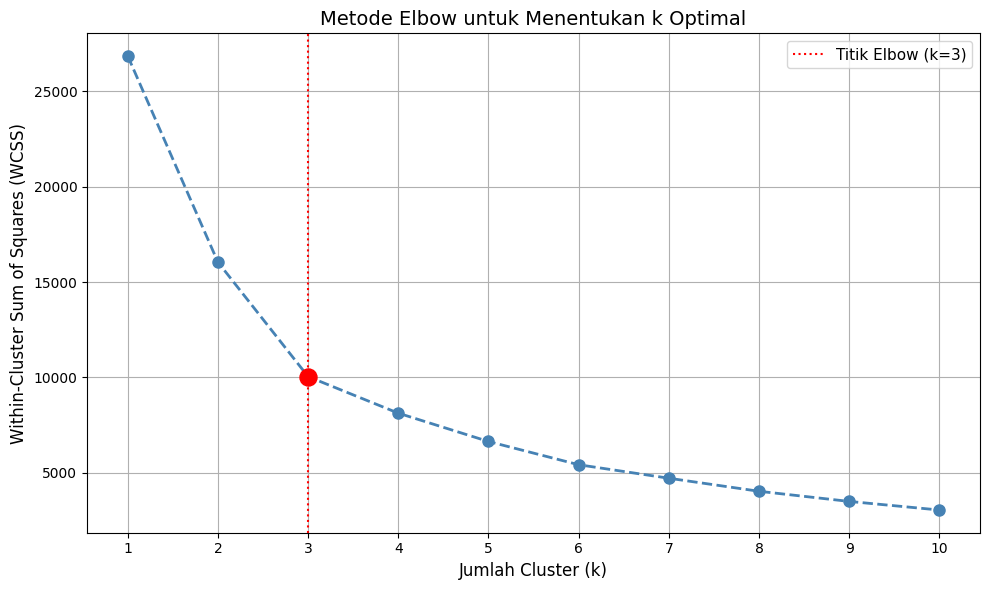

In [ ]:
# Visualisasi Grafik Elbow
plt.figure(figsize=(10, 6))
plt.plot(k_values, wcss, marker='o', linestyle='--', color='steelblue',
         linewidth=2, markersize=8)

# Tandai titik elbow (k=3)
plt.axvline(x=3, color='red', linestyle=':', linewidth=1.5, label='Titik Elbow (k=3)')
plt.scatter([3], [wcss[2]], color='red', s=150, zorder=5)

plt.xlabel('Jumlah Cluster (k)', fontsize=12)
plt.ylabel('Within-Cluster Sum of Squares (WCSS)', fontsize=12)
plt.title('Metode Elbow untuk Menentukan k Optimal', fontsize=14)
plt.xticks(k_values)
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Membangun model K-Means dengan k=3
k_optimal = 3
kmeans_model = KMeans(n_clusters=k_optimal, random_state=42, n_init=10)
kmeans_model.fit(X_scaled)

# Menambahkan label cluster
df_selected['Cluster'] = kmeans_model.labels_
df['Cluster'] = kmeans_model.labels_
df_processed['Cluster'] = kmeans_model.labels_

print(f'Model K-Means dengan k={k_optimal} berhasil dibangun!')
print('\nDistribusi jumlah anggota setiap cluster:')
for i, count in df['Cluster'].value_counts().sort_index().items():
    print(f'  Cluster {i+1}: {count} nasabah ({count/len(df)*100:.1f}%)')

# Himpunan Pusat Cluster Akhir (skala asli)
centroids_scaled = kmeans_model.cluster_centers_
centroids_original = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_original, columns=selected_features)
print('\nHimpunan Pusat Cluster Akhir (nilai asli):')
print(centroids_df)

Model K-Means dengan k=3 berhasil dibangun!

Distribusi jumlah anggota setiap cluster:
  Cluster 1: 5357 nasabah (59.9%)
  Cluster 2: 1950 nasabah (21.8%)
  Cluster 3: 1643 nasabah (18.4%)

Himpunan Pusat Cluster Akhir (nilai asli):
       BALANCE    PURCHASES  CASH_ADVANCE
0   658.908423   375.772350    228.319272
1  3240.592900   423.519682   2282.426299
2  1580.674680  2288.815390    209.823953


## **b. Evaluasi Model Clustering**

In [ ]:
# Evaluasi Silhouette Score
sil_score = silhouette_score(X_scaled, kmeans_model.labels_)
print(f'Silhouette Score untuk k={k_optimal}: {sil_score:.4f}')

if sil_score >= 0.4:
    print(f'\u2713 Silhouette Score {sil_score:.4f} >= 0.4 => Clustering BAIK!')
else:
    print(f'\u2717 Silhouette Score {sil_score:.4f} < 0.4 => Clustering KURANG BAIK')

# Perbandingan untuk berbagai k
print('\nPerbandingan Silhouette Score untuk berbagai k:')
sil_scores = []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    sil_scores.append(sil)
    status = '\u2713' if sil >= 0.4 else '\u2717'
    print(f'  {status} k={k}: Silhouette Score = {sil:.4f}')

Silhouette Score untuk k=3: 0.4912
✓ Silhouette Score 0.4912 >= 0.4 => Clustering BAIK!

Perbandingan Silhouette Score untuk berbagai k:
  ✓ k=2: Silhouette Score = 0.4740
  ✓ k=3: Silhouette Score = 0.4912
  ✓ k=4: Silhouette Score = 0.4647
  ✓ k=5: Silhouette Score = 0.4652
  ✓ k=6: Silhouette Score = 0.4506
  ✓ k=7: Silhouette Score = 0.4037
  ✓ k=8: Silhouette Score = 0.4128


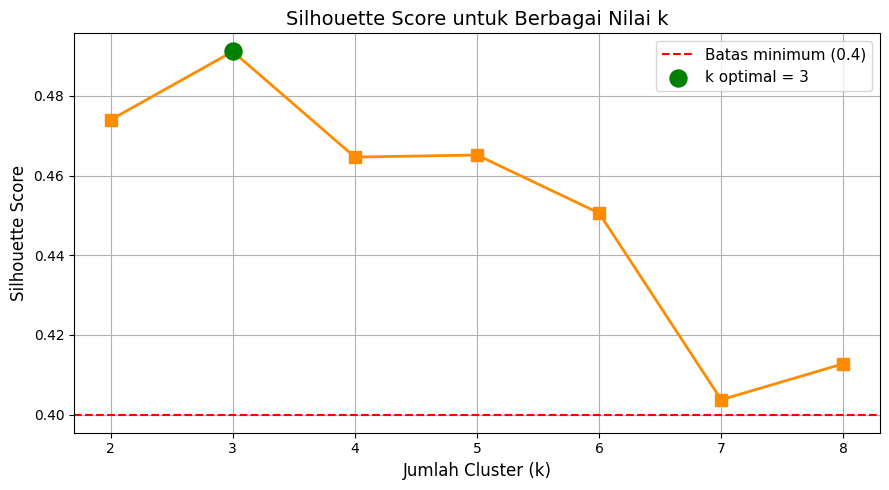

In [ ]:
# Visualisasi Silhouette Score untuk berbagai k
plt.figure(figsize=(9, 5))
plt.plot(list(k_range), sil_scores, marker='s', linestyle='-', color='darkorange', linewidth=2, markersize=8)
plt.axhline(y=0.4, color='red', linestyle='--', linewidth=1.5, label='Batas minimum (0.4)')
plt.scatter([k_optimal], [sil_score], color='green', s=150, zorder=5, label=f'k optimal = {k_optimal}')
plt.xlabel('Jumlah Cluster (k)', fontsize=12)
plt.ylabel('Silhouette Score', fontsize=12)
plt.title('Silhouette Score untuk Berbagai Nilai k', fontsize=14)
plt.xticks(list(k_range))
plt.legend(fontsize=11)
plt.grid(True)
plt.tight_layout()
plt.show()

## **c. Visualisasi Hasil Clustering**

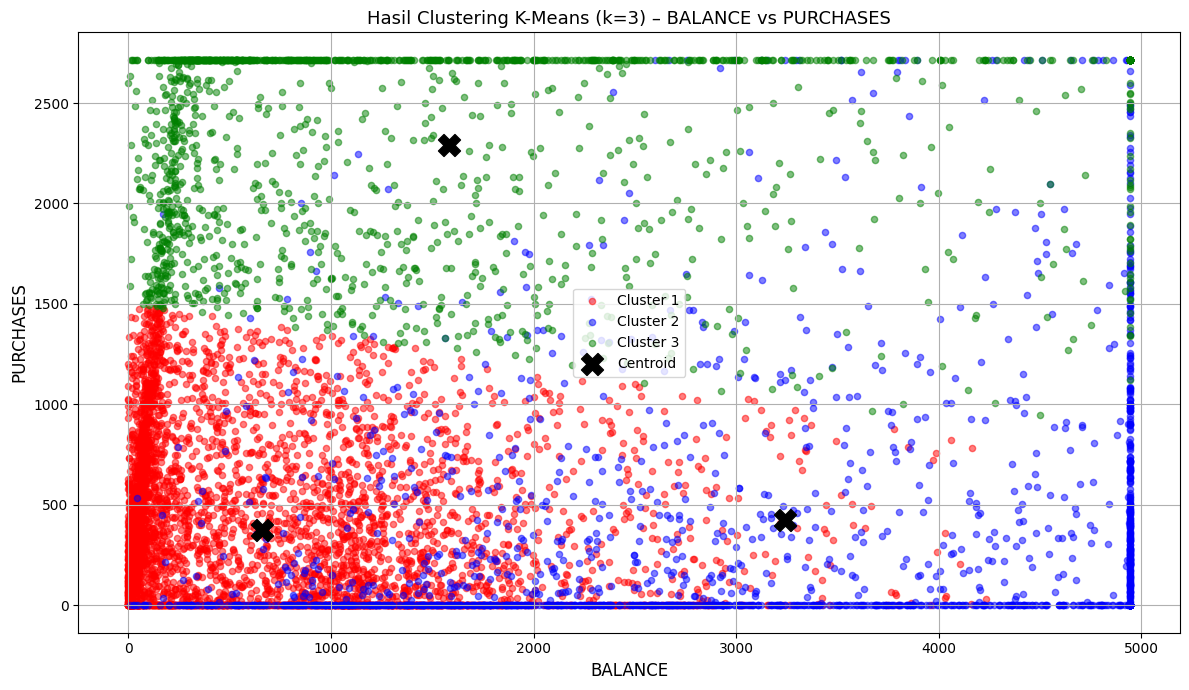

In [ ]:
# Visualisasi: BALANCE vs PURCHASES
colors = ['red', 'blue', 'green']

plt.figure(figsize=(12, 7))
for cluster_idx in range(k_optimal):
    mask = df['Cluster'] == cluster_idx
    plt.scatter(
        df_processed.loc[mask, 'BALANCE'],
        df_processed.loc[mask, 'PURCHASES'],
        c=colors[cluster_idx],
        label=f'Cluster {cluster_idx + 1}',
        alpha=0.5, s=20)

plt.scatter(
    centroids_df['BALANCE'], centroids_df['PURCHASES'],
    c='black', marker='X', s=250, zorder=6, label='Centroid')
plt.xlabel('BALANCE', fontsize=12)
plt.ylabel('PURCHASES', fontsize=12)
plt.title(f'Hasil Clustering K-Means (k={k_optimal}) \u2013 BALANCE vs PURCHASES', fontsize=13)
plt.legend(fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.show()

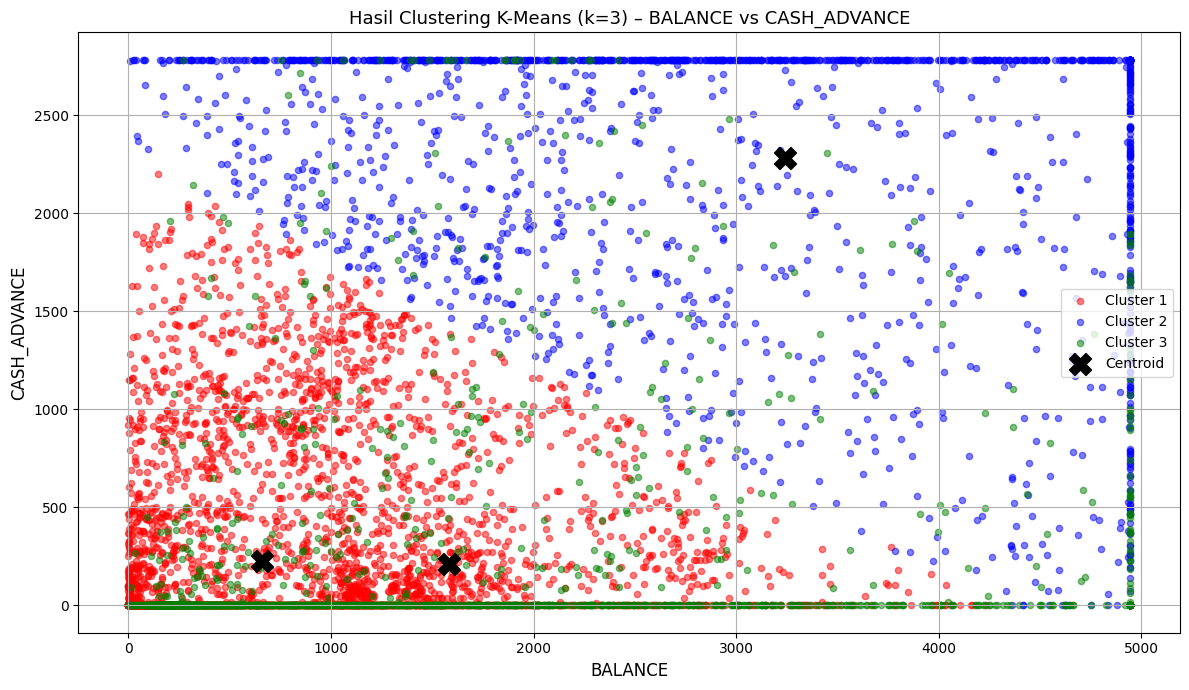

In [ ]:
# Visualisasi: BALANCE vs CASH_ADVANCE
plt.figure(figsize=(12, 7))
for cluster_idx in range(k_optimal):
    mask = df['Cluster'] == cluster_idx
    plt.scatter(
        df_processed.loc[mask, 'BALANCE'],
        df_processed.loc[mask, 'CASH_ADVANCE'],
        c=colors[cluster_idx],
        label=f'Cluster {cluster_idx + 1}',
        alpha=0.5, s=20)

plt.scatter(
    centroids_df['BALANCE'], centroids_df['CASH_ADVANCE'],
    c='black', marker='X', s=250, zorder=6, label='Centroid')
plt.xlabel('BALANCE', fontsize=12)
plt.ylabel('CASH_ADVANCE', fontsize=12)
plt.title(f'Hasil Clustering K-Means (k={k_optimal}) \u2013 BALANCE vs CASH_ADVANCE', fontsize=13)
plt.legend(fontsize=10)
plt.grid(True)
plt.tight_layout()
plt.show()

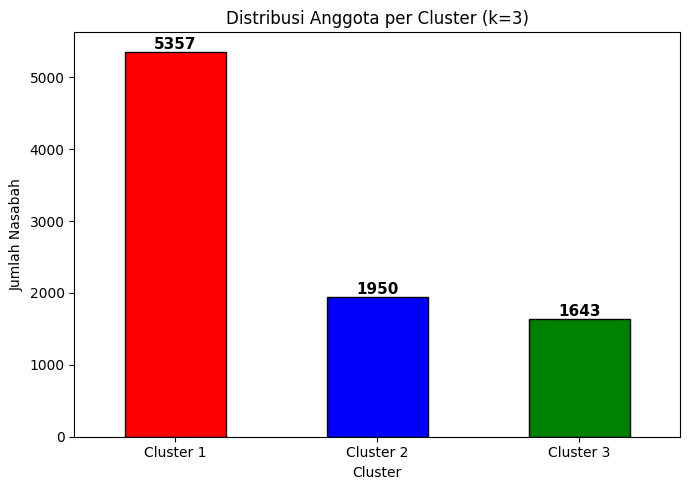

In [ ]:
# Bar chart distribusi anggota per cluster
cluster_dist = df['Cluster'].value_counts().sort_index()
plt.figure(figsize=(7, 5))
cluster_dist.plot(kind='bar', color=colors, edgecolor='black')
plt.title(f'Distribusi Anggota per Cluster (k={k_optimal})')
plt.xlabel('Cluster')
plt.ylabel('Jumlah Nasabah')
plt.xticks([0, 1, 2], ['Cluster 1', 'Cluster 2', 'Cluster 3'], rotation=0)
for i, v in enumerate(cluster_dist.values):
    plt.text(i, v + 30, str(v), ha='center', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## **d. Analisis dan Interpretasi Hasil Cluster**

In [ ]:
# Rata-rata fitur clustering per cluster
cluster_summary_sel = df_processed[selected_features + ['Cluster']].groupby('Cluster').mean().round(2)
print('Rata-rata Fitur Clustering per Cluster:')
print(cluster_summary_sel)

# Rata-rata fitur tambahan per cluster
extra_features = ['CREDIT_LIMIT', 'PAYMENTS', 'PURCHASES_FREQUENCY',
                  'CASH_ADVANCE_FREQUENCY', 'PRC_FULL_PAYMENT', 'TENURE']
cluster_summary_extra = df[extra_features + ['Cluster']].groupby('Cluster').mean().round(4)
print('\nRata-rata Fitur Tambahan per Cluster:')
print(cluster_summary_extra)

Rata-rata Fitur Clustering per Cluster:
         BALANCE  PURCHASES  CASH_ADVANCE
Cluster                                  
0         659.00     375.57        228.36
1        3240.59     423.52       2282.43
2        1579.82    2288.32        209.70

Rata-rata Fitur Tambahan per Cluster:
         CREDIT_LIMIT   PAYMENTS  PURCHASES_FREQUENCY  CASH_ADVANCE_FREQUENCY  \
Cluster                                                                         
0           3164.9723   791.8629               0.4529                  0.0754   
1           6509.9852  2934.7506               0.2811                  0.3725   
2           6436.2539  3376.0584               0.8608                  0.0481   

         PRC_FULL_PAYMENT   TENURE  
Cluster                             
0                  0.1654  11.4685  
1                  0.0347  11.3872  
2                  0.2568  11.8308  


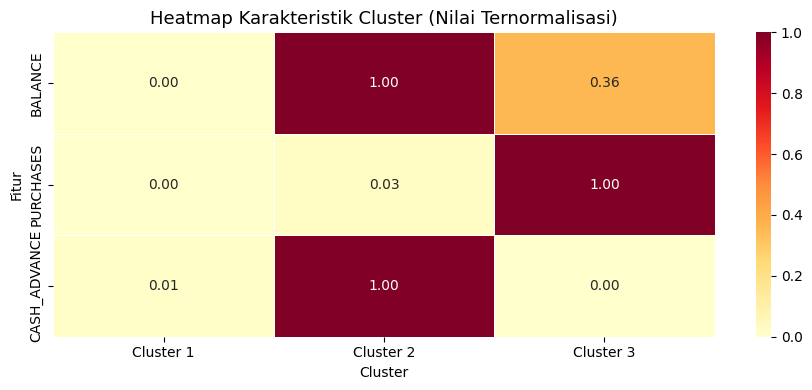

In [ ]:
# Heatmap karakteristik cluster (nilai ternormalisasi)
all_features_summary = df_processed[selected_features + ['Cluster']].groupby('Cluster').mean()
all_norm = (all_features_summary - all_features_summary.min()) / \
           (all_features_summary.max() - all_features_summary.min())

plt.figure(figsize=(9, 4))
sns.heatmap(all_norm.T, annot=True, cmap='YlOrRd', fmt='.2f', linewidths=0.5,
            xticklabels=['Cluster 1', 'Cluster 2', 'Cluster 3'])
plt.title('Heatmap Karakteristik Cluster (Nilai Ternormalisasi)', fontsize=13)
plt.xlabel('Cluster')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

In [ ]:
# Detail interpretasi setiap cluster
print('=' * 70)
print('INTERPRETASI HASIL CLUSTERING')
print('=' * 70)

for cluster_id in range(k_optimal):
    n_members = (df['Cluster'] == cluster_id).sum()
    pct = n_members / len(df) * 100
    print(f'\nCluster {cluster_id + 1} (n={n_members} nasabah, {pct:.1f}% dari total):')
    print(f'  BALANCE              : {cluster_summary_sel.loc[cluster_id, "BALANCE"]:.2f}')
    print(f'  PURCHASES            : {cluster_summary_sel.loc[cluster_id, "PURCHASES"]:.2f}')
    print(f'  CASH_ADVANCE         : {cluster_summary_sel.loc[cluster_id, "CASH_ADVANCE"]:.2f}')
    print(f'  CREDIT_LIMIT         : {cluster_summary_extra.loc[cluster_id, "CREDIT_LIMIT"]:.2f}')
    print(f'  PAYMENTS             : {cluster_summary_extra.loc[cluster_id, "PAYMENTS"]:.2f}')
    print(f'  PURCHASES_FREQUENCY  : {cluster_summary_extra.loc[cluster_id, "PURCHASES_FREQUENCY"]:.4f}')
    print(f'  CASH_ADV_FREQUENCY   : {cluster_summary_extra.loc[cluster_id, "CASH_ADVANCE_FREQUENCY"]:.4f}')
    print(f'  PRC_FULL_PAYMENT     : {cluster_summary_extra.loc[cluster_id, "PRC_FULL_PAYMENT"]:.4f}')

INTERPRETASI HASIL CLUSTERING

Cluster 1 (n=5357 nasabah, 59.9% dari total):
  BALANCE              : 659.00
  PURCHASES            : 375.57
  CASH_ADVANCE         : 228.36
  CREDIT_LIMIT         : 3164.97
  PAYMENTS             : 791.86
  PURCHASES_FREQUENCY  : 0.4529
  CASH_ADV_FREQUENCY   : 0.0754
  PRC_FULL_PAYMENT     : 0.1654

Cluster 2 (n=1950 nasabah, 21.8% dari total):
  BALANCE              : 3240.59
  PURCHASES            : 423.52
  CASH_ADVANCE         : 2282.43
  CREDIT_LIMIT         : 6509.99
  PAYMENTS             : 2934.75
  PURCHASES_FREQUENCY  : 0.2811
  CASH_ADV_FREQUENCY   : 0.3725
  PRC_FULL_PAYMENT     : 0.0347

Cluster 3 (n=1643 nasabah, 18.4% dari total):
  BALANCE              : 1579.82
  PURCHASES            : 2288.32
  CASH_ADVANCE         : 209.70
  CREDIT_LIMIT         : 6436.25
  PAYMENTS             : 3376.06
  PURCHASES_FREQUENCY  : 0.8608
  CASH_ADV_FREQUENCY   : 0.0481
  PRC_FULL_PAYMENT     : 0.2568


# Interpretasi dan Kesimpulan
Berdasarkan hasil analisis menggunakan metode K-Means dengan jumlah cluster (k) = 3 serta nilai Silhouette Score ≥ 0.4, diperoleh tiga kelompok nasabah dengan karakteristik yang cukup berbeda satu sama lain.

Cluster 1: Nasabah Aktif Berbelanja

Cluster ini didominasi oleh nasabah dengan saldo relatif rendah, yang menunjukkan bahwa mereka cenderung tidak memiliki banyak tunggakan. Aktivitas pembelian tergolong tinggi dan frekuensi transaksi juga sering, sementara penggunaan cash advance sangat rendah. Secara umum, nasabah pada kelompok ini aktif menggunakan kartu kredit untuk berbelanja dan cukup disiplin dalam melakukan pembayaran. Segmen ini berpotensi untuk diberikan program seperti cashback, reward, atau promo lainnya.

Cluster 2: Nasabah Pengguna Cash Advance

Pada cluster ini terlihat bahwa nilai saldo cukup tinggi, sedangkan aktivitas pembelian relatif rendah. Sebaliknya, penggunaan cash advance sangat tinggi dan dilakukan dengan frekuensi yang sering. Hal ini menunjukkan bahwa nasabah dalam kelompok ini lebih banyak memanfaatkan kartu kredit sebagai sumber dana tunai dibandingkan untuk berbelanja. Dari sisi bisnis, kelompok ini perlu mendapat perhatian lebih karena berpotensi memiliki risiko kredit yang lebih besar.

Cluster 3: Nasabah Moderat

Cluster ketiga berisi nasabah dengan nilai saldo, pembelian, dan frekuensi transaksi yang cenderung berada di tingkat menengah hingga rendah. Penggunaan cash advance juga relatif kecil. Kelompok ini dapat dikatakan sebagai pengguna kartu kredit yang tidak terlalu aktif. Oleh karena itu, diperlukan strategi khusus seperti promo atau penawaran menarik agar mereka lebih sering menggunakan kartu kredit.

*Kesimpulan*

Hasil clustering yang diperoleh dapat dikatakan cukup baik dalam mengelompokkan nasabah berdasarkan pola penggunaan kartu kredit. Hal ini terlihat dari nilai Silhouette Score yang berada di atas 0.4, yang menandakan bahwa antar cluster sudah cukup terpisah dengan baik.

Selain itu, setiap cluster memiliki karakteristik yang berbeda secara jelas, baik dari sisi saldo, aktivitas pembelian, maupun penggunaan cash advance. Interpretasi yang dihasilkan juga relevan dengan kondisi nyata, sehingga dapat dimanfaatkan untuk berbagai keperluan seperti strategi pemasaran, pengelolaan risiko, dan peningkatan loyalitas pelanggan.